# Reading a frame across a production change

**Frame F11116, central California, 2016-07 to 2026-04 (389 granules).**

DISP-S1 granules produced from November 2025 store `displacement` as
float64 and `time` as float seconds since 2010; earlier productions store
float32 and seconds since each acquisition. A frame that runs past October
2024 mixes the two. This notebook shows what changed, what disp-xr does
about it, and that the chained series runs on without a break at the
boundary. Details are in the [product notes](../product_notes.md).

This notebook ran on real granules; its outputs are saved, and the
documentation build does not run it again.

In [1]:
import warnings
from collections import Counter
from pathlib import Path

import dask.array
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import disp_xr as dxr
from disp_xr.product import MixedPrecisionWarning

warnings.simplefilter("ignore", dask.array.PerformanceWarning)

frame = Path("/u/aurora-r0/govorcin/01_OPERA/DISP/data/F11116")
granules = dxr.find_products(frame)
productions = granules.production_time.dt.strftime("%Y-%m")
print(f"{len(granules)} granules")
print(Counter(productions))

389 granules
Counter({'2025-04': 314, '2025-11': 45, '2026-08': 30})


## What changed between productions

One granule from each production, read with h5py: the dtype of every 2D
layer and how `time` is encoded.

In [2]:
rows = []
for month, group in granules.groupby(productions):
    with h5py.File(group.path.iloc[-1]) as f:
        rows.append(
            {
                "production": month,
                "displacement": str(f["displacement"].dtype),
                "temporal_coherence": str(f["temporal_coherence"].dtype),
                "time units": (
                    f["time"].attrs["units"].decode()
                    if isinstance(f["time"].attrs["units"], bytes)
                    else f["time"].attrs["units"]
                ),
                "first secondary date": f"{group.secondary_time.min():%Y-%m-%d}",
            }
        )
pd.DataFrame(rows)

,production,displacement,temporal_coherence,time units,first secondary date
0,2025-04,float32,float32,seconds since 2024-10-03 14:08:37.435763,2016-07-29
1,2025-11,float64,float32,seconds since 2010-01-01 00:00:00.000000,2024-10-15
2,2026-08,float64,float32,seconds since 2010-01-01 00:00:00.000000,2025-10-28


Only `displacement` changes dtype; every other layer is the same. The time
encoding changes too, and the later style decodes a few nanoseconds off.

## Opening the whole frame

`open_disp` reads productions that differ only in float precision
together: it warns, casts to float32 and records the layer. It reads times
to the whole second, so ministacks chain across the boundary.

In [3]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", MixedPrecisionWarning)
    ds = dxr.open_disp(frame, layers=["displacement", "temporal_coherence"])
print(str(caught[0].message).splitlines()[0])
print("dtype:", ds.displacement.dtype, "| mixed:", ds.attrs["mixed_precision"])
print("sub-second times:", int((ds.time.dt.microsecond != 0).sum()))

stack = dxr.stack_disp(ds)
print(
    f"chained: {stack.sizes['time']} epochs,"
    f" {stack.time.values[0]!s:.10} to {stack.time.values[-1]!s:.10}"
)

Granules store ['displacement'] at different float precisions; they are read together and cast to float32:
dtype: float32 | mixed: ['displacement']
sub-second times: 0


chained: 390 epochs, 2016-07-05 to 2026-04-26


## The series runs on across the boundary

A pixel near the middle of the frame, referenced to the median of a 2 km box
around it (a small read; a scene-wide median would read every pixel of
every epoch). The dashed line marks the first ministack of the November
2025 production.

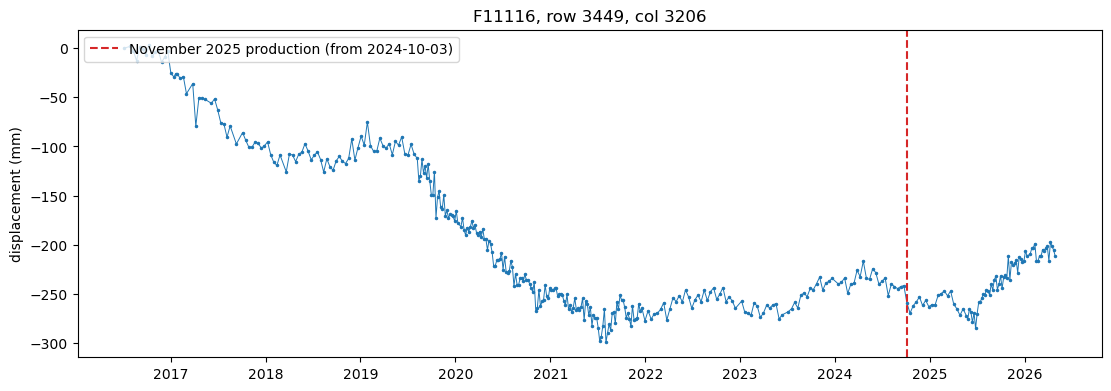

step across the boundary: -10.2 mm
typical step between epochs (median |step|): 6.5 mm


In [4]:
row, col = stack.sizes["y"] // 2, stack.sizes["x"] // 3
box = stack.displacement.isel(y=slice(row - 33, row + 34), x=slice(col - 33, col + 34))
series = (box - box.median(("y", "x"))).isel(y=33, x=33).compute()
boundary = granules.loc[productions >= "2025-11", "reference_time"].min()

fig, ax = plt.subplots(figsize=(11, 3.8), layout="constrained")
ax.plot(series.time, 1e3 * series, ".-", ms=3, lw=0.7)
ax.axvline(
    boundary,
    color="C3",
    ls="--",
    label=f"November 2025 production (from {boundary:%Y-%m-%d})",
)
ax.set(ylabel="displacement (mm)", title=f"F11116, row {row}, col {col}")
ax.legend(loc="upper left")
plt.show()

valid = series.dropna("time")
steps = 1e3 * valid.diff("time")
across = steps.sel(time=valid.time[valid.time > np.datetime64(boundary)][0])
print(f"step across the boundary: {float(across):+.1f} mm")
print(
    f"typical step between epochs (median |step|): {float(abs(steps).median()):.1f} mm"
)